In [7]:
# Import libraries and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Dataset loaded successfully!")

Saving Telco-Customer-Churn.csv to Telco-Customer-Churn.csv
Dataset loaded successfully!


In [8]:
# Initial dataset inspection

print("Dataset dimensions:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset dimensions: (7043, 21)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecu

In [9]:
# Data quality inspection

# 1. Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 3. Investigate TotalCharges
total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("\nInvalid or blank TotalCharges values:",
      total_charges_numeric.isnull().sum())

# 4. Examine the target variable
print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

# 5. Summarize numerical variables
print("\nNumerical variable summary:")
display(df[["SeniorCitizen", "tenure", "MonthlyCharges"]].describe())

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Number of duplicate rows: 0

Invalid or blank TotalCharges values: 11

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Numerical variable summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
# Investigate invalid or blank TotalCharges values

# Convert TotalCharges to numeric temporarily
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Select rows where conversion produced a missing value
invalid_rows = df[total_charges_numeric.isna()]

# Display relevant information
print("Number of affected records:", len(invalid_rows))

display(
    invalid_rows[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Number of affected records: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [11]:
# Clean the TotalCharges column

# Create a separate copy of the original dataset
df_clean = df.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Replace missing TotalCharges with 0 for zero-tenure customers
mask = (
    df_clean["TotalCharges"].isna()
    & (df_clean["tenure"] == 0)
)

df_clean.loc[mask, "TotalCharges"] = 0

# Verify the cleaning
print("Remaining missing values in TotalCharges:",
      df_clean["TotalCharges"].isna().sum())

print("\nNew TotalCharges data type:",
      df_clean["TotalCharges"].dtype)

print("\nCleaned dataset dimensions:", df_clean.shape)

display(df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].head())

Remaining missing values in TotalCharges: 0

New TotalCharges data type: float64

Cleaned dataset dimensions: (7043, 21)


,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65


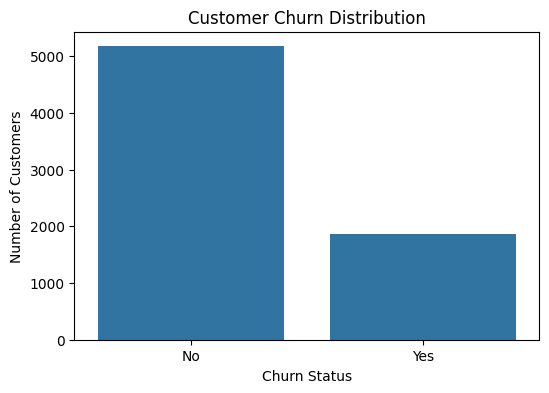

In [12]:
# Visualize the target variable

plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

Average tenure by churn status:


,tenure
Churn,
No,37.569965
Yes,17.979133


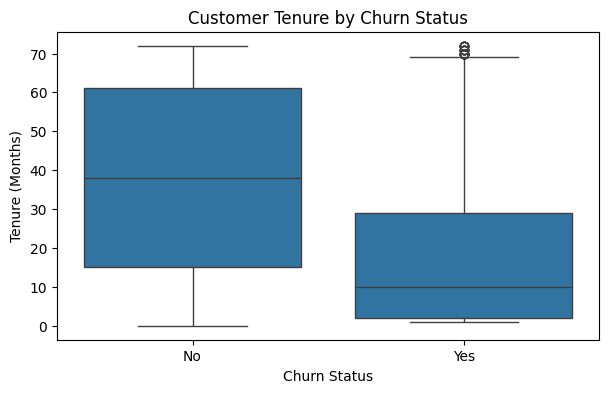

In [13]:
#Investigate the relationship between tenure and churn

print("Average tenure by churn status:")
display(df_clean.groupby("Churn")["tenure"].mean())

plt.figure(figsize=(7, 4))

sns.boxplot(data=df_clean, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()

Churn percentage within each contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


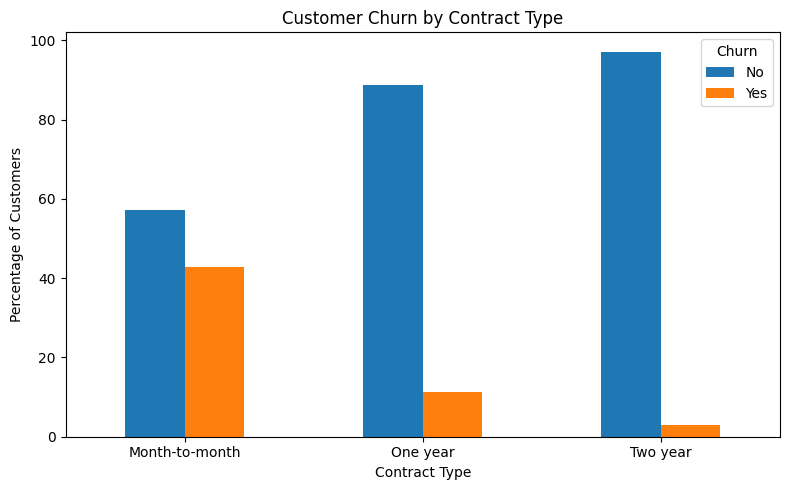

In [14]:
# Investigate churn across contract types

contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print("Churn percentage within each contract type:")
display(contract_churn.round(2))

# Visualize the results
contract_churn.plot(kind="bar", figsize=(8, 5))

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

Average monthly charges by churn status:


,MonthlyCharges
Churn,
No,61.27
Yes,74.44


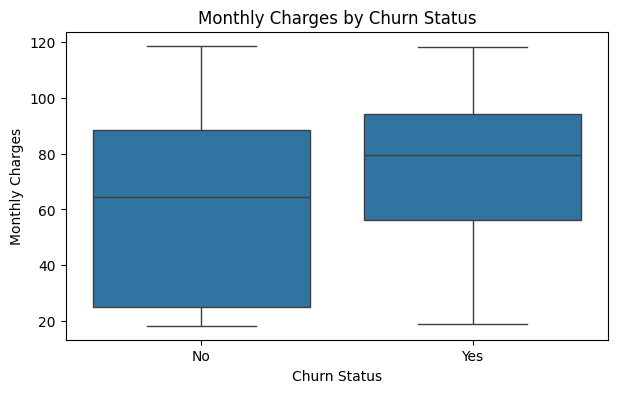

In [15]:
# Investigate monthly charges and churn

print("Average monthly charges by churn status:")

display(
    df_clean.groupby("Churn")["MonthlyCharges"].mean().round(2)
)

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.00,0.02,0.22,0.10
tenure,0.02,1.00,0.25,0.83
MonthlyCharges,0.22,0.25,1.00,0.65
TotalCharges,0.10,0.83,0.65,1.00


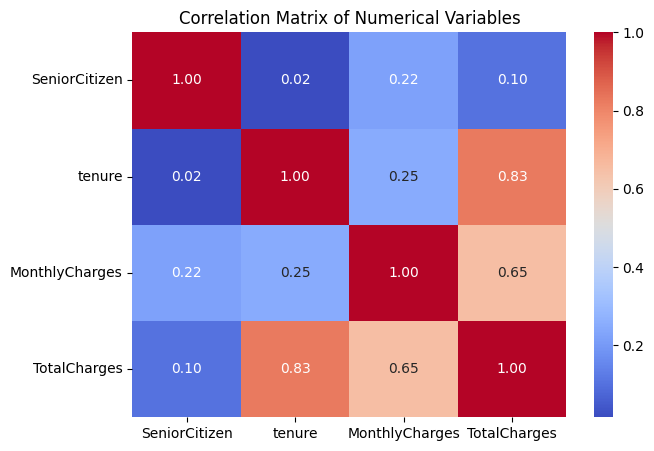

In [16]:
# Correlation analysis of numerical variables

numerical_df = df_clean[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
]

correlation_matrix = numerical_df.corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

In [17]:

# Separate input features (X) and target variable (y)

# Remove columns that should not be used as predictors
X = df_clean.drop(
    columns=["customerID", "Churn", "TotalCharges"]
)

# Convert the target into binary values
y = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Display the resulting shapes
print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Feature matrix shape: (7043, 18)
Target variable shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [18]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the resulting dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (5634, 18)
Testing features: (1409, 18)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [19]:

# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 3
Number of categorical features: 15


In [20]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Preprocess numerical and categorical features separately
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [21]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model using training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [22]:

# Predict churn for the testing dataset
y_pred = logistic_model.predict(X_test)

# Calculate churn probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Display predictions for the first 10 customers
results = pd.DataFrame({
    "Actual Churn": y_test.values[:10],
    "Predicted Churn": y_pred[:10],
    "Churn Probability": y_prob[:10]
})

print(results)


   Actual Churn  Predicted Churn  Churn Probability
0             0                0           0.087854
1             0                1           0.866936
2             0                0           0.153840
3             0                1           0.669163
4             0                0           0.063226
5             0                1           0.822488
6             0                1           0.720893
7             0                0           0.309074
8             0                0           0.015223
9             1                1           0.642764


In [23]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
print("LOGISTIC REGRESSION - EVALUATION")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


LOGISTIC REGRESSION - EVALUATION
--------------------------------
Accuracy: 0.7402413058907026
Precision: 0.506993006993007
Recall: 0.7754010695187166
F1-Score: 0.6131078224101479
ROC-AUC: 0.8385181740680461

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.73      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[753 282]
 [ 84 290]]


In [24]:

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the Decision Tree
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [25]:

# Predict churn using Decision Tree
dt_pred = decision_tree_model.predict(X_test)

# Calculate churn probabilities
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

# Display predictions for the first 10 customers
dt_results = pd.DataFrame({
    "Actual Churn": y_test.values[:10],
    "Predicted Churn": dt_pred[:10],
    "Churn Probability": dt_prob[:10]
})

print(dt_results)


   Actual Churn  Predicted Churn  Churn Probability
0             0                0           0.000000
1             0                1           0.877580
2             0                0           0.251263
3             0                1           0.752336
4             0                0           0.024274
5             0                1           0.620549
6             0                1           0.620549
7             0                0           0.389587
8             0                0           0.024274
9             1                0           0.389587


In [26]:

print("DECISION TREE - EVALUATION")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1-Score:", f1_score(y_test, dt_pred))
print("ROC-AUC:", roc_auc_score(y_test, dt_prob))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))


DECISION TREE - EVALUATION
---------------------------
Accuracy: 0.7579843860894251
Precision: 0.5301645338208409
Recall: 0.7754010695187166
F1-Score: 0.6297502714440825
ROC-AUC: 0.8340463458110517

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409


Confusion Matrix:
[[778 257]
 [ 84 290]]


In [27]:

# Compare the performance of both models

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, dt_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, dt_pred)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, dt_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, dt_prob)
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print(comparison.round(4).to_string(index=False))


MODEL PERFORMANCE COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.7402     0.5070  0.7754    0.6131   0.8385
      Decision Tree    0.7580     0.5302  0.7754    0.6298   0.8340


TOP 15 IMPORTANT FEATURES
                            Feature  Importance
       cat__Contract_Month-to-month    0.613844
                        num__tenure    0.127936
   cat__InternetService_Fiber optic    0.108954
                num__MonthlyCharges    0.053187
             cat__Contract_Two year    0.022955
                cat__TechSupport_No    0.019626
             cat__OnlineSecurity_No    0.012831
              cat__PhoneService_Yes    0.011736
cat__PaymentMethod_Electronic check    0.010991
                cat__Dependents_Yes    0.005621
    cat__PaymentMethod_Mailed check    0.004056
            cat__StreamingMovies_No    0.003979
                 num__SeniorCitizen    0.002702
                    cat__Partner_No    0.001158
               cat__OnlineBackup_No    0.000424


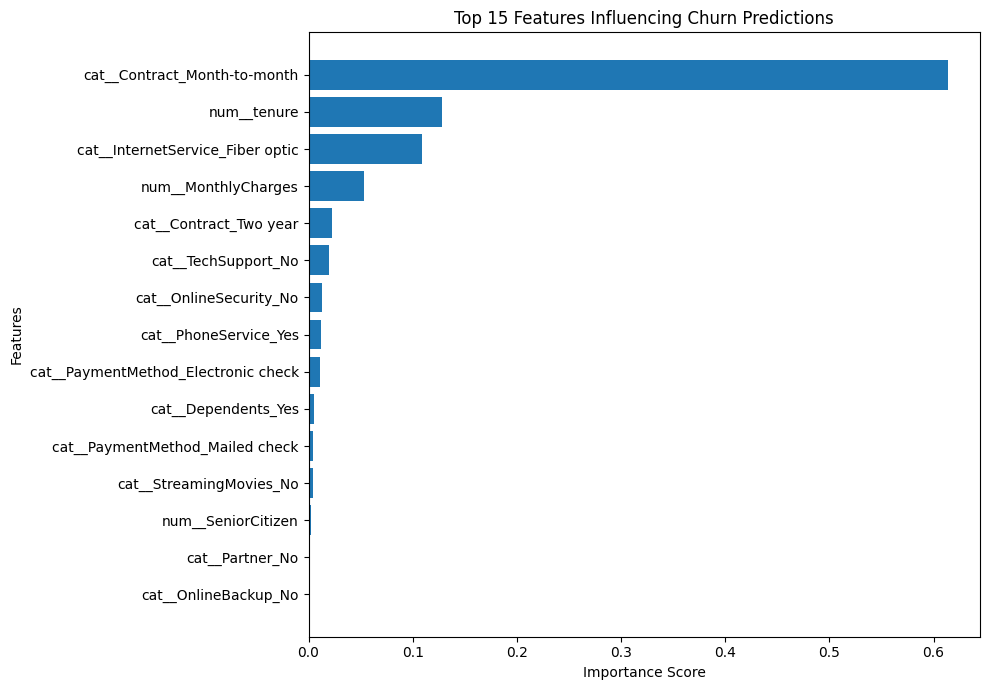

In [28]:

import matplotlib.pyplot as plt
import pandas as pd

# Get feature names after preprocessing
feature_names = decision_tree_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance scores
importance_scores = decision_tree_model.named_steps[
    "classifier"
].feature_importances_

# Create a DataFrame of feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
print("TOP 15 IMPORTANT FEATURES")
print(feature_importance.head(15).to_string(index=False))

# Visualize feature importance
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Churn Predictions")
plt.tight_layout()
plt.show()


In [29]:

# Extract feature names from the preprocessing pipeline
feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = logistic_model.named_steps[
    "classifier"
].coef_[0]

# Create a DataFrame
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("TOP 15 LOGISTIC REGRESSION COEFFICIENTS")
print(
    coefficient_df.head(15)[
        ["Feature", "Coefficient"]
    ].to_string(index=False)
)


TOP 15 LOGISTIC REGRESSION COEFFICIENTS
                                  Feature  Coefficient
                   cat__Contract_Two year    -0.768221
                              num__tenure    -0.755286
         cat__InternetService_Fiber optic     0.734116
             cat__Contract_Month-to-month     0.657027
                 cat__InternetService_DSL    -0.642905
                      num__MonthlyCharges    -0.572944
                 cat__StreamingMovies_Yes     0.293601
                     cat__StreamingTV_Yes     0.281679
                  cat__InternetService_No    -0.277610
  cat__OnlineSecurity_No internet service    -0.277610
     cat__TechSupport_No internet service    -0.277610
cat__DeviceProtection_No internet service    -0.277610
    cat__OnlineBackup_No internet service    -0.277610
 cat__StreamingMovies_No internet service    -0.277610
     cat__StreamingTV_No internet service    -0.277610


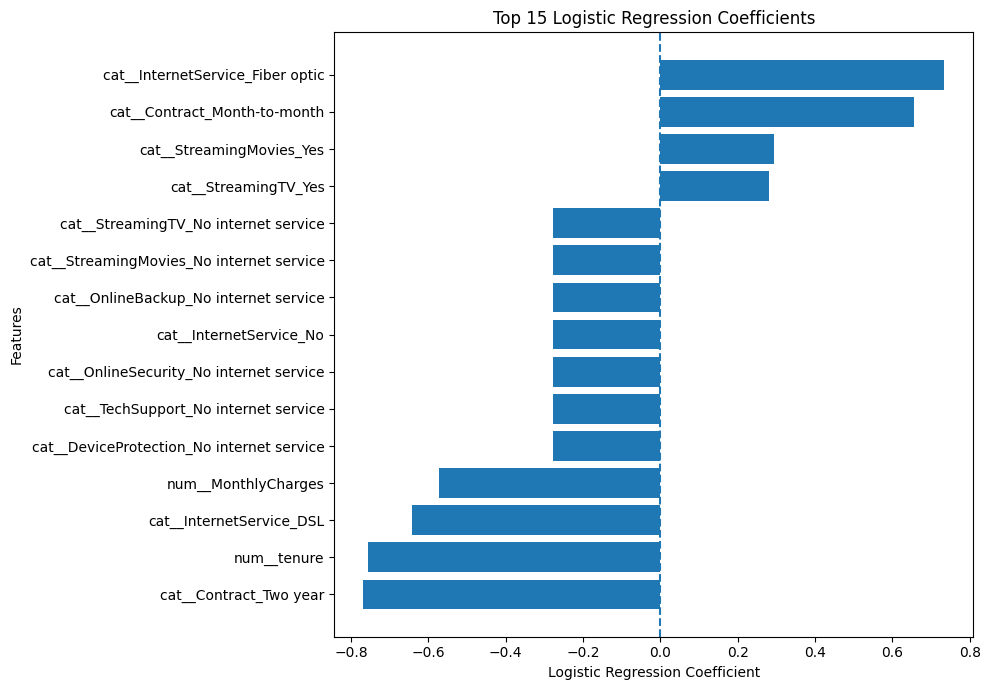

In [30]:

# Select the 15 largest coefficients by absolute magnitude
top_coefficients = coefficient_df.head(15).copy()

# Sort for horizontal plotting
top_coefficients = top_coefficients.sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"]
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Logistic Regression Coefficients")

plt.tight_layout()
plt.show()


In [31]:

def predict_customer_churn(customer_data):

    # Convert customer information into a DataFrame
    customer_df = pd.DataFrame([customer_data])

    # Predict churn class
    prediction = logistic_model.predict(customer_df)[0]

    # Calculate churn probability
    probability = logistic_model.predict_proba(customer_df)[0][1]

    # Assign risk category
    if probability < 0.30:
        risk = "Low Risk"
    elif probability < 0.60:
        risk = "Medium Risk"
    else:
        risk = "High Risk"

    return prediction, probability, risk


print("Customer churn prediction function created successfully!")


Customer churn prediction function created successfully!


In [32]:

import ipywidgets as widgets
from IPython.display import display, clear_output

# Create input fields
gender = widgets.Dropdown(
    options=["Male", "Female"],
    description="Gender:"
)

senior = widgets.Dropdown(
    options=[("No", 0), ("Yes", 1)],
    description="Senior Citizen:"
)

partner = widgets.Dropdown(
    options=["Yes", "No"],
    description="Partner:"
)

dependents = widgets.Dropdown(
    options=["Yes", "No"],
    description="Dependents:"
)

tenure = widgets.IntSlider(
    value=12, min=0, max=72,
    description="Tenure:"
)

phone = widgets.Dropdown(
    options=["Yes", "No"],
    description="Phone Service:"
)

multiple_lines = widgets.Dropdown(
    options=["Yes", "No", "No phone service"],
    description="Multiple Lines:"
)

internet = widgets.Dropdown(
    options=["DSL", "Fiber optic", "No"],
    description="Internet:"
)

online_security = widgets.Dropdown(
    options=["Yes", "No", "No internet service"],
    description="Online Security:"
)

online_backup = widgets.Dropdown(
    options=["Yes", "No", "No internet service"],
    description="Online Backup:"
)

device_protection = widgets.Dropdown(
    options=["Yes", "No", "No internet service"],
    description="Device Protection:"
)

tech_support = widgets.Dropdown(
    options=["Yes", "No", "No internet service"],
    description="Tech Support:"
)

streaming_tv = widgets.Dropdown(
    options=["Yes", "No", "No internet service"],
    description="Streaming TV:"
)

streaming_movies = widgets.Dropdown(
    options=["Yes", "No", "No internet service"],
    description="Streaming Movies:"
)

contract = widgets.Dropdown(
    options=["Month-to-month", "One year", "Two year"],
    description="Contract:"
)

paperless = widgets.Dropdown(
    options=["Yes", "No"],
    description="Paperless Billing:"
)

payment = widgets.Dropdown(
    options=[
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ],
    description="Payment:"
)

monthly_charges = widgets.FloatText(
    value=70.0,
    description="Monthly Charges:"
)


# Output area
output = widgets.Output()

# Prediction button
predict_button = widgets.Button(
    description="Predict Churn",
    button_style="success"
)

# Display interface
inputs = [
    gender, senior, partner, dependents, tenure,
    phone, multiple_lines, internet, online_security,
    online_backup, device_protection, tech_support,
    streaming_tv, streaming_movies, contract,
    paperless, payment, monthly_charges
]

display(widgets.VBox(inputs + [predict_button, output]))
def on_predict_button_clicked(b):

    customer_data = {
        "gender": gender.value,
        "SeniorCitizen": senior.value,
        "Partner": partner.value,
        "Dependents": dependents.value,
        "tenure": tenure.value,
        "PhoneService": phone.value,
        "MultipleLines": multiple_lines.value,
        "InternetService": internet.value,
        "OnlineSecurity": online_security.value,
        "OnlineBackup": online_backup.value,
        "DeviceProtection": device_protection.value,
        "TechSupport": tech_support.value,
        "StreamingTV": streaming_tv.value,
        "StreamingMovies": streaming_movies.value,
        "Contract": contract.value,
        "PaperlessBilling": paperless.value,
        "PaymentMethod": payment.value,
        "MonthlyCharges": monthly_charges.value,
    }

    with output:
        output.clear_output(wait=True)

        prediction, probability, risk = predict_customer_churn(customer_data)

        print("CUSTOMER CHURN PREDICTION")
        print("-------------------------")
        print("Prediction:", "Yes - Likely to Churn" if prediction == 1 else "No - Unlikely to Churn")
        print(f"Churn Probability: {probability:.2%}")
        print("Risk Category:", risk)


predict_button.on_click(on_predict_button_clicked)